In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import matplotlib.patches as mpatches
import sys

# --- 设置绘图风格 ---
sns.set_theme(style="whitegrid")
plt.rcParams.update({'font.size': 12})
# plt.rcParams['font.sans-serif'] = ['SimHei'] # 如需中文请取消注释

# --- 1. 数据加载与变量合成 ---
csv_filename = 'optimized_data_final.csv'
try:
    df = pd.read_csv(csv_filename)
    print(f"成功加载数据: {csv_filename}")
    df.columns = df.columns.str.strip() # 清理列名空格

    # ==========================================================================
    # 【核心步骤】变量合成 (Variable Composite)
    # ==========================================================================
    print("\n正在进行变量合成...")
    
    # 1. 性别识别准确性 (直接使用原列，稍后映射为数字)
    # 假设源数据中已经是 'Accurate' 和 'Misrecognized' 这样的文本
    if 'Gender_accuracy' not in df.columns:
        print("错误：找不到列 'Gender_accuracy'。")
        sys.exit()

    # 2. 广告怀疑论 (Ad Skepticism)
    # 计算 Q1-Q8 的平均分作为“信任得分”
    trust_cols = [f'Q{i}_Trust_{suffix}' for i, suffix in enumerate(
        ['Depend', 'Aim_Inform', 'Is_Informative', 'Truthful', 'Reliable', 
         'Truth_Well_Told', 'True_Picture', 'Accurately_Informed'], start=1)]
    
    # 检查列是否存在
    if not all(col in df.columns for col in trust_cols):
        print("错误：缺少计算信任得分的列 (Q1-Q8)。请检查列名拼写。")
        sys.exit()

    # 【关键假设】假设问卷是 5 点量表 (1=低信任, 5=高信任)。
    # 怀疑论 = 6 - 信任平均分。这样处理后，得分越高代表越怀疑。
    # 如果你的量表是 7 点，请把 6 改为 8。
    MAX_SCALE_VALUE = 5 
    df['Trust_Score_Avg'] = df[trust_cols].mean(axis=1)
    df['Ad_Skepticism'] = (MAX_SCALE_VALUE + 1) - df['Trust_Score_Avg']
    print(f" - 已合成 'Ad_Skepticism' (基于 {len(trust_cols)} 个题项，假设为{MAX_SCALE_VALUE}点反向计分)")

    # 3. 感知侵入性 (Perceived Intrusiveness)
    # 计算 Q23-Q27 的平均分
    intrusive_cols = ['Q23_Intrusive', 'Q24_Disturbing', 'Q25_Irritating', 
                      'Q26_Invasive', 'Q27_Uncomfortable']
    if not all(col in df.columns for col in intrusive_cols):
        print("错误：缺少计算侵入性的列 (Q23-Q27)。")
        sys.exit()
    df['Perceived_Intrusiveness'] = df[intrusive_cols].mean(axis=1)
    print(f" - 已合成 'Perceived_Intrusiveness' (基于 {len(intrusive_cols)} 个题项)")

    # 4. 购买意愿 (Purchase Intention)
    # 计算 Q20-Q22 的平均分
    purchase_cols = ['Q20_Purchase_Interest', 'Q21_Purchase_Thoughts', 
                     'Q22_Purchase_Probability']
    if not all(col in df.columns for col in purchase_cols):
        print("错误：缺少计算购买意愿的列 (Q20-Q22)。")
        sys.exit()
    df['Purchase_Intention'] = df[purchase_cols].mean(axis=1)
    print(f" - 已合成 'Purchase_Intention' (基于 {len(purchase_cols)} 个题项)")

    # 5. 将性别准确性文本映射为数字 (用于相关性分析)
    # 请根据你的实际数据修改这里的键值对。例如，如果是 'Yes'/'No'，就改为 {'Yes': 1, 'No': 0}
    # 这里假设数据中是 'Accurate' 和 'Misrecognized'（根据你的论文内容）
    map_dict = {'Accurate': 1, 'Misrecognized': 0} 
    
    # 检查数据中的实际值
    actual_values = df['Gender_accuracy'].unique()
    print(f" - 'Gender_accuracy' 列中的实际值有: {actual_values}")
    
    # 如果实际值不是 Accurate/Misrecognized，尝试一种通用的映射方法（需要你确认）
    # 例如，如果数据是 1 和 2，你需要知道哪个代表准确。
    # 假设：如果数据不是预期的文本，则尝试直接转换（适用原始数据就是0/1的情况）
    if not set(map_dict.keys()).issubset(set(actual_values)):
         print("⚠️ 注意：'Gender_accuracy' 中的值与预期的 'Accurate'/'Misrecognized' 不符。")
         print("尝试直接将该列转换为数值类型用于相关性计算...")
         try:
             df['Gender_Accuracy_Code'] = pd.to_numeric(df['Gender_accuracy'])
             # 重新创建一个用于绘图的文本列，假设 1=Accurate, 0=Misrecognized
             df['Gender_Accuracy_Text'] = df['Gender_Accuracy_Code'].map({1: 'Accurate', 0: 'Misrecognized'})
         except:
             print("❌ 错误：无法将 'Gender_accuracy' 转换为数值。请检查数据内容并修改代码中的 `map_dict`。")
             sys.exit()
    else:
        # 如果数据符合预期
        df['Gender_Accuracy_Code'] = df['Gender_accuracy'].map(map_dict)
        df['Gender_Accuracy_Text'] = df['Gender_accuracy'] # 用于绘图的分组列

    print("变量合成完成！\n")

except FileNotFoundError:
    print(f"❌ 错误：找不到文件 '{csv_filename}'。")
    sys.exit()
except Exception as e:
    print(f"发生未知错误: {e}")
    sys.exit()


# --- 图表生成部分 (使用合成后的变量) ---

# ==============================================================================
# 图1：隐私悖论与侵入性对比图
# ==============================================================================
print("正在生成图1...")
# 检查用于绘图的分组列是否有空值
if df['Gender_Accuracy_Text'].isnull().any():
    print("⚠️ 警告：'Gender_Accuracy_Text' 存在空值，这些行将在图1中被忽略。")
    plot_df = df.dropna(subset=['Gender_Accuracy_Text'])
else:
    plot_df = df

# 确保绘图顺序的类别在数据中存在
available_cats = plot_df['Gender_Accuracy_Text'].unique()
plot_order = [cat for cat in ['Accurate', 'Misrecognized'] if cat in available_cats]

if not plot_order:
    print("❌ 无法生成图1：数据中没有 'Accurate' 或 'Misrecognized' 类别。")
else:
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    palette = {"Accurate": "#1f77b4", "Misrecognized": "#ff7f0e"}

    # 左图：怀疑论
    sns.boxplot(x="Gender_Accuracy_Text", y="Ad_Skepticism", data=plot_df, ax=axes[0],
                palette=palette, order=plot_order, width=0.5)
    sns.stripplot(x="Gender_Accuracy_Text", y="Ad_Skepticism", data=plot_df, ax=axes[0],
                  color=".2", alpha=0.6, jitter=True, order=plot_order)
    axes[0].set_title("The Skepticism Paradox\n(Higher Accuracy -> Higher Skepticism)", fontweight='bold')
    axes[0].set_ylabel("Ad Skepticism Score (Higher = More Skeptical)")
    axes[0].set_xlabel("Gender Recognition Accuracy")

    # 右图：侵入性
    sns.boxplot(x="Gender_Accuracy_Text", y="Perceived_Intrusiveness", data=plot_df, ax=axes[1],
                palette=palette, order=plot_order, width=0.5)
    sns.stripplot(x="Gender_Accuracy_Text", y="Perceived_Intrusiveness", data=plot_df, ax=axes[1],
                  color=".2", alpha=0.6, jitter=True, order=plot_order)
    axes[1].set_title("Intrusiveness & Misrecognition\n(Misrecognition -> Higher Intrusiveness)", fontweight='bold')
    axes[1].set_ylabel("Perceived Intrusiveness Score")
    axes[1].set_xlabel("Gender Recognition Accuracy")

    fig.suptitle("The Divergent Impact of Gender Recognition Accuracy", fontsize=16, y=1.02)
    plt.tight_layout()
    plt.savefig("Fig1_Privacy_Paradox_Contrast.png", dpi=300, bbox_inches='tight')
    print("图1已保存。")

# ==============================================================================
# 图3：相关性热力图
# ==============================================================================
print("\n正在生成图3...")
corr_cols = ['Gender_Accuracy_Code', 'Ad_Skepticism', 'Perceived_Intrusiveness', 'Purchase_Intention']
# 删除任何包含空值的行以进行相关性计算
corr_df = df[corr_cols].dropna()

if len(corr_df) < 5:
    print("❌ 数据不足，无法生成相关性热力图。")
else:
    corr_matrix = corr_df.corr()
    
    fig, ax = plt.subplots(figsize=(8, 7))
    cmap = sns.diverging_palette(240, 10, as_cmap=True)
    
    # 简化的标签用于展示
    labels = ['Gender Accuracy', 'Ad Skepticism', 'Perceived\nIntrusiveness', 'Purchase\nIntention']
    
    sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap=cmap, vmin=-1, vmax=1, center=0,
                xticklabels=labels, yticklabels=labels,
                square=True, linewidths=.5, annot_kws={"size": 12, "weight": "bold"})
    
    ax.set_title("Correlation Heatmap: Key Study Variables", fontweight='bold', y=1.02)
    plt.xticks(rotation=0)
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.savefig("Fig3_Correlation_Heatmap.png", dpi=300, bbox_inches='tight')
    print("图3已保存。")

# 图2和图4不依赖于 CSV 数据，可以使用之前的代码生成。
# 为保持脚本简洁，此处省略，请结合上一个回复中的代码使用。

print("\n脚本运行完毕。请检查生成的 PNG 文件。")

成功加载数据: optimized_data_final.csv

正在进行变量合成...
错误：缺少计算信任得分的列 (Q1-Q8)。请检查列名拼写。


SystemExit: 

/opt/miniconda3/envs/coding3/lib/python3.12/site-packages/IPython/core/interactiveshell.py:3678: UserWarning: To exit: use 'exit', 'quit', or Ctrl-D.
  warn("To exit: use 'exit', 'quit', or Ctrl-D.", stacklevel=1)


In [7]:
import pandas as pd

# 读取文件
df = pd.read_csv('optimized_data_final.csv')
# 清理列名首尾空格
df.columns = df.columns.str.strip()

print("CSV 文件中的所有列名：")
print("=" * 30)
# 打印出所有包含 'Q' 的列名，方便查找
q_columns = [col for col in df.columns if 'Q' in col]
for col in q_columns:
    print(repr(col))
print("=" * 30)

CSV 文件中的所有列名：
'Q1_Trust_Depend'
'Q2_Aim_Inform'
'Q3_Is_Informative'
'Q4_Trust_Truthful'
'Q5_Trust_Reliable'
'Q6_Trust_Truth_Well_Told'
'Q7_Trust_True_Picture'
'Q8_Trust_Accurately_Informed'
'Q9_Essential_Info'
'Q10_Relevance_Matches_Needs'
'Q11_Relevance_Tailor_Made'
'Q12_Relevance_Tailored_Situation'
'Q13_Relevance_Unique_Customer'
'Q14_Relevance_Customized_Needs'
'Q15_Beneficial'
'Q16_Important'
'Q17_Useful'
'Q18_Meaningful'
'Q19_Valuable'
'Q20_Purchase_Interest'
'Q21_Purchase_Thoughts'
'Q22_Purchase_Probability'
'Q23_Intrusive'
'Q24_Disturbing'
'Q25_Irritating'
'Q26_Invasive'
'Q27_Uncomfortable'


成功加载数据: optimized_data_final.csv
数据形状: (25, 33)

--- 开始变量合成 ---
提示：怀疑论计算假设为 5 点量表反向计分。
已找到性别准确性列: 'Gender_accuracy'
 - 实际值: ['5' '3' '4']
✅ 已合成 'Ad_Skepticism' (基于 8 个题项)
✅ 已合成 'Perceived_Intrusiveness' (基于 5 个题项)
✅ 已合成 'Purchase_Intention' (基于 3 个题项)
--- 变量合成成功 ---

正在生成图1...
❌ 错误：有效数据不足，无法生成图1。

正在生成图2...
图2已保存。

正在生成图3...
❌ 数据不足，无法生成相关性热力图。

正在生成图4...
图4已保存。

🎉 所有图表生成完毕！请查看当前目录下的 PNG 文件。


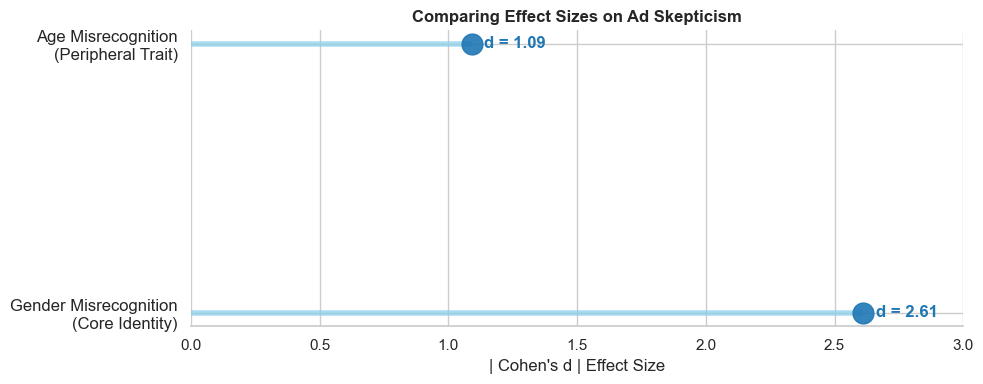

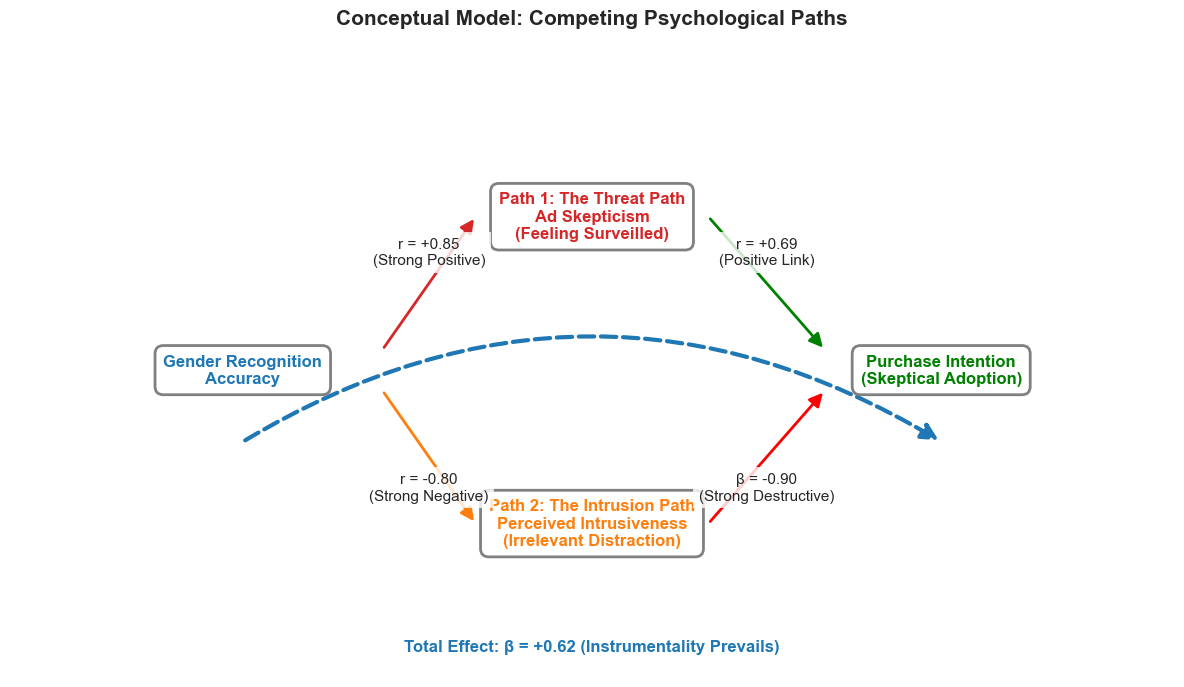

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import matplotlib.patches as mpatches
import sys

# --- 设置绘图风格 ---
sns.set_theme(style="whitegrid")
plt.rcParams.update({'font.size': 12})

# --- 1. 数据加载 ---
csv_filename = 'optimized_data_final.csv'
try:
    df = pd.read_csv(csv_filename)
    # 清理列名首尾空格，这是一个好习惯
    df.columns = df.columns.str.strip()
    print(f"成功加载数据: {csv_filename}")
    print(f"数据形状: {df.shape}")

except FileNotFoundError:
    print(f"❌ 错误：找不到文件 '{csv_filename}'。")
    sys.exit()

# ==============================================================================
# 【核心步骤】变量合成 (Variable Composite)
# ==============================================================================
print("\n--- 开始变量合成 ---")

try:
    # --- 关键设置：请确认你的量表点数 ---
    # 如果是7点量表，请改为 7
    MAX_SCALE_VALUE = 5
    print(f"提示：怀疑论计算假设为 {MAX_SCALE_VALUE} 点量表反向计分。")

    # 1. 性别识别准确性 (Gender_accuracy)
    # --------------------------------------------------
    ga_col = 'Gender_accuracy' # 根据你提供的列名
    if ga_col not in df.columns:
        # 尝试忽略大小写查找
        ga_col = next((col for col in df.columns if col.lower() == 'gender_accuracy'), None)
        if ga_col is None:
             print(f"❌ 错误：未找到列 '{ga_col}'。请检查 CSV。")
             sys.exit()

    print(f"已找到性别准确性列: '{ga_col}'")

    # 映射文本到数值
    map_dict = {}
    actual_values = df[ga_col].astype(str).str.strip().unique()
    print(f" - 实际值: {actual_values}")
    
    for val in actual_values:
        val_lower = val.lower()
        # 匹配你数据中可能出现的词
        if val_lower in ['accurate', 'yes', 'true', '1']:
            map_dict[val] = 1
        elif val_lower in ['misrecognized', 'no', 'false', '0', 'inaccurate']:
            map_dict[val] = 0
            
    df['Gender_Accuracy_Code'] = df[ga_col].astype(str).str.strip().map(map_dict)
    df['Gender_Accuracy_Text'] = df['Gender_Accuracy_Code'].map({1: 'Accurate', 0: 'Misrecognized'})


    # 2. 广告怀疑论 (Ad Skepticism) - Q1 to Q8
    # --------------------------------------------------
    # 【直接复制你的列名列表】确保完全一致
    trust_cols = [
        'Q1_Trust_Depend', 'Q2_Aim_Inform', 'Q3_Is_Informative', 'Q4_Trust_Truthful',
        'Q5_Trust_Reliable', 'Q6_Trust_Truth_Well_Told', 'Q7_Trust_True_Picture',
        'Q8_Trust_Accurately_Informed'
    ]
    
    # 检查这些列是否真的都在 df.columns 里
    missing_trust = [col for col in trust_cols if col not in df.columns]
    if missing_trust:
        print(f"❌ 错误：CSV 中缺少以下信任列: {missing_trust}")
        print("请再次运行诊断代码确认列名。")
        sys.exit()

    # 计算平均分并反向计分
    # 确保数据是数值型
    for col in trust_cols:
        df[col] = pd.to_numeric(df[col], errors='coerce')
        
    df['Trust_Score_Avg'] = df[trust_cols].mean(axis=1)
    df['Ad_Skepticism'] = (MAX_SCALE_VALUE + 1) - df['Trust_Score_Avg']
    print(f"✅ 已合成 'Ad_Skepticism' (基于 {len(trust_cols)} 个题项)")


    # 3. 感知侵入性 (Perceived Intrusiveness) - Q23 to Q27
    # --------------------------------------------------
    # 【直接复制你的列名列表】
    intrusive_cols = [
        'Q23_Intrusive', 'Q24_Disturbing', 'Q25_Irritating', 
        'Q26_Invasive', 'Q27_Uncomfortable'
    ]
    
    missing_intrusive = [col for col in intrusive_cols if col not in df.columns]
    if missing_intrusive:
        print(f"❌ 错误：CSV 中缺少以下侵入性列: {missing_intrusive}")
        sys.exit()

    for col in intrusive_cols:
        df[col] = pd.to_numeric(df[col], errors='coerce')

    df['Perceived_Intrusiveness'] = df[intrusive_cols].mean(axis=1)
    print(f"✅ 已合成 'Perceived_Intrusiveness' (基于 {len(intrusive_cols)} 个题项)")


    # 4. 购买意愿 (Purchase Intention) - Q20 to Q22
    # --------------------------------------------------
    # 【直接复制你的列名列表】
    purchase_cols = [
        'Q20_Purchase_Interest', 'Q21_Purchase_Thoughts', 'Q22_Purchase_Probability'
    ]
    
    missing_purchase = [col for col in purchase_cols if col not in df.columns]
    if missing_purchase:
        print(f"❌ 错误：CSV 中缺少以下购买意愿列: {missing_purchase}")
        sys.exit()

    for col in purchase_cols:
        df[col] = pd.to_numeric(df[col], errors='coerce')

    df['Purchase_Intention'] = df[purchase_cols].mean(axis=1)
    print(f"✅ 已合成 'Purchase_Intention' (基于 {len(purchase_cols)} 个题项)")

    print("--- 变量合成成功 ---\n")

except Exception as e:
    print(f"\n❌ 变量合成过程中发生错误: {e}")
    import traceback
    traceback.print_exc()
    sys.exit()


# ==============================================================================
# 图表生成部分
# ==============================================================================

# --- 图1：隐私悖论与侵入性对比图 ---
print("正在生成图1...")
# 使用合成后的变量，并删除包含空值的行
plot_df = df.dropna(subset=['Gender_Accuracy_Text', 'Ad_Skepticism', 'Perceived_Intrusiveness'])

if plot_df.empty:
    print("❌ 错误：有效数据不足，无法生成图1。")
else:
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    palette = {"Accurate": "#1f77b4", "Misrecognized": "#ff7f0e"}
    order = ['Accurate', 'Misrecognized']
    
    existing_cats = plot_df['Gender_Accuracy_Text'].unique()
    plot_order = [cat for cat in order if cat in existing_cats]

    if not plot_order:
        print("❌ 错误：数据中不存在 'Accurate' 或 'Misrecognized' 类别。")
    else:
        # 左图
        sns.boxplot(x="Gender_Accuracy_Text", y="Ad_Skepticism", data=plot_df, ax=axes[0], 
                    palette=palette, order=plot_order, width=0.5)
        sns.stripplot(x="Gender_Accuracy_Text", y="Ad_Skepticism", data=plot_df, ax=axes[0], 
                      color=".2", alpha=0.6, jitter=True, order=plot_order)
        axes[0].set_title("The Skepticism Paradox", fontweight='bold')
        axes[0].set_ylabel("Ad Skepticism Score")
        
        # 右图
        sns.boxplot(x="Gender_Accuracy_Text", y="Perceived_Intrusiveness", data=plot_df, ax=axes[1], 
                    palette=palette, order=plot_order, width=0.5)
        sns.stripplot(x="Gender_Accuracy_Text", y="Perceived_Intrusiveness", data=plot_df, ax=axes[1], 
                      color=".2", alpha=0.6, jitter=True, order=plot_order)
        axes[1].set_title("Intrusiveness & Misrecognition", fontweight='bold')
        axes[1].set_ylabel("Perceived Intrusiveness Score")
        
        fig.suptitle("Divergent Impact of Gender Recognition Accuracy", fontsize=16, y=1.02)
        plt.tight_layout()
        plt.savefig("Fig1_Privacy_Paradox_Contrast.png", dpi=300, bbox_inches='tight')
        print("图1已保存。")


# --- 图2：效应量对比图 (数据来自文本) ---
print("\n正在生成图2...")
effect_data = {
    'Dimension': ['Gender Misrecognition\n(Core Identity)', 'Age Misrecognition\n(Peripheral Trait)'],
    'Cohen_d': [2.61, 1.09]
}
df_effect = pd.DataFrame(effect_data)
fig, ax = plt.subplots(figsize=(10, 4))
ax.hlines(y=df_effect.index, xmin=0, xmax=df_effect['Cohen_d'], color='skyblue', alpha=0.7, linewidth=4)
ax.plot(df_effect['Cohen_d'], df_effect.index, "o", markersize=15, color='#1f77b4', alpha=0.9)
for i, v in enumerate(df_effect['Cohen_d']):
    ax.text(v + 0.05, i, f"d = {v:.2f}", va='center', fontweight='bold', fontsize=12, color='#1f77b4')
ax.set_yticks(df_effect.index)
ax.set_yticklabels(df_effect['Dimension'], fontsize=12)
ax.set_xlabel("| Cohen's d | Effect Size")
ax.set_title("Comparing Effect Sizes on Ad Skepticism", fontweight='bold')
ax.set_xlim(0, 3.0)
sns.despine(left=True, bottom=False)
plt.tight_layout()
plt.savefig("Fig2_Effect_Size_Comparison.png", dpi=300, bbox_inches='tight')
print("图2已保存。")


# --- 图3：相关性热力图 ---
print("\n正在生成图3...")
corr_cols = ['Gender_Accuracy_Code', 'Ad_Skepticism', 'Perceived_Intrusiveness', 'Purchase_Intention']
corr_df = df[corr_cols].dropna()

if len(corr_df) < 5:
    print("❌ 数据不足，无法生成相关性热力图。")
else:
    corr_matrix = corr_df.corr()
    fig, ax = plt.subplots(figsize=(8, 7))
    cmap = sns.diverging_palette(240, 10, as_cmap=True)
    labels = ['Gender Accuracy', 'Ad Skepticism', 'Perceived\nIntrusiveness', 'Purchase\nIntention']
    sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap=cmap, vmin=-1, vmax=1, center=0,
                xticklabels=labels, yticklabels=labels,
                square=True, linewidths=.5, annot_kws={"size": 12, "weight": "bold"})
    ax.set_title("Correlation Heatmap", fontweight='bold', y=1.02)
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.savefig("Fig3_Correlation_Heatmap.png", dpi=300, bbox_inches='tight')
    print("图3已保存。")


# --- 图4：概念路径图 (纯绘图) ---
print("\n正在生成图4...")
fig, ax = plt.subplots(figsize=(12, 7))
ax.set_xlim(0, 10)
ax.set_ylim(0, 6)
ax.axis('off')
node_style = dict(boxstyle="round,pad=0.5", fc="white", ec="gray", lw=2)
text_style = dict(ha='center', va='center', fontsize=12, fontweight='bold', bbox=node_style)
ax.text(2, 3, "Gender Recognition\nAccuracy", **text_style, color='#1f77b4')
ax.text(5, 4.5, "Path 1: The Threat Path\nAd Skepticism\n(Feeling Surveilled)", **text_style, color='#d62728')
ax.text(5, 1.5, "Path 2: The Intrusion Path\nPerceived Intrusiveness\n(Irrelevant Distraction)", **text_style, color='#ff7f0e')
ax.text(8, 3, "Purchase Intention\n(Skeptical Adoption)", **text_style, color='green')

def draw_arrow(start, end, label, color='black', text_pos='center'):
    arrow = mpatches.FancyArrowPatch(start, end, connectionstyle="arc3,rad=0",
                                     arrowstyle='-|>', mutation_scale=20, color=color, lw=2)
    ax.add_patch(arrow)
    mid_x, mid_y = (start[0] + end[0]) / 2, (start[1] + end[1]) / 2
    if text_pos == 'top': mid_y += 0.3
    elif text_pos == 'bottom': mid_y -= 0.3
    ax.text(mid_x, mid_y, label, ha='center', va='center', fontsize=11, 
            bbox=dict(facecolor='white', edgecolor='none', alpha=0.8))

draw_arrow((3.2, 3.2), (4, 4.5), "r = +0.85\n(Strong Positive)", color='#d62728', text_pos='top')
draw_arrow((3.2, 2.8), (4, 1.5), "r = -0.80\n(Strong Negative)", color='#ff7f0e', text_pos='bottom')
draw_arrow((6, 4.5), (7, 3.2), "r = +0.69\n(Positive Link)", color='green', text_pos='top')
draw_arrow((6, 1.5), (7, 2.8), "β = -0.90\n(Strong Destructive)", color='red', text_pos='bottom')
total_arrow = mpatches.FancyArrowPatch((2, 2.3), (8, 2.3), connectionstyle="arc3,rad=-0.3",
                                       arrowstyle='-|>', mutation_scale=25, color='#1f77b4', lw=3, linestyle='--')
ax.add_patch(total_arrow)
ax.text(5, 0.3, "Total Effect: β = +0.62 (Instrumentality Prevails)", ha='center', va='center', 
        fontsize=12, fontweight='bold', color='#1f77b4', bbox=dict(facecolor='white', alpha=0.9))
ax.set_title("Conceptual Model: Competing Psychological Paths", fontsize=15, fontweight='bold', y=1.05)
plt.tight_layout()
plt.savefig("Fig4_Conceptual_Path_Diagram.png", dpi=300, bbox_inches='tight')
print("图4已保存。")

print("\n🎉 所有图表生成完毕！请查看当前目录下的 PNG 文件。")

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

# --- 配置部分 (保持不变) ---
tickers = ['AAPL', 'MSFT', 'GOOG', 'AMZN', 'TSLA']
weights = np.array([0.2, 0.2, 0.2, 0.2, 0.2])
start_date = '2018-01-01'
end_date = '2023-12-31'
initial_portfolio_value = 100000
num_simulations = 1000
time_horizon_years = 5

# --- 数据加载与预处理 (保持不变，使用模拟数据代替yfinance) ---
num_days_history = 1500
num_tickers = len(tickers)
np.random.seed(42)
historical_prices = np.random.uniform(low=50, high=200, size=(num_days_history, num_tickers))
adj_close_df = pd.DataFrame(historical_prices, columns=tickers)
returns_df = adj_close_df.pct_change().dropna()
avg_daily_returns = returns_df.mean()
cov_matrix = returns_df.cov()

# --- 蒙特卡洛模拟 (保持不变) ---
num_days = int(time_horizon_years * 252)
np.random.seed(101)
simulated_daily_returns = np.random.multivariate_normal(
    avg_daily_returns, cov_matrix, (num_days, num_simulations)
)
simulated_cumulative_returns = np.exp(np.cumsum(simulated_daily_returns, axis=0))
portfolio_values = initial_portfolio_value * simulated_cumulative_returns
start_values = np.full((1, num_simulations), initial_portfolio_value)
portfolio_values = np.vstack([start_values, portfolio_values])

# --- 绘图 ---
plt.figure(figsize=(12, 10))

# --- 子图 1: 模拟路径折线图叠加热力图 ---
plt.subplot(2, 1, 1)

# 1. 准备热力图数据
# 将时间和价值数据展平
time_points = np.tile(np.arange(num_days + 1), num_simulations)
flattened_values = portfolio_values.T.flatten()

# 设置热力图的区间 (bins)
num_bins_time = num_days + 1  # 每个交易日一个区间
num_bins_value = 100          # 价值区间数量，可以根据需要调整
value_range = (np.min(portfolio_values), np.max(portfolio_values))

# 使用二维直方图统计每个区间的路径数量
heatmap_data, x_edges, y_edges = np.histogram2d(
    time_points,
    flattened_values,
    bins=[num_bins_time, num_bins_value],
    range=[[0, num_days], value_range]
)

# 使用对数色标来增强低频区域的可见度 (可选)
norm = mcolors.LogNorm(vmin=1, vmax=heatmap_data.max())

# 2. 绘制热力图
# imshow 需要转置数据，并将原点设置在左下角
plt.imshow(
    heatmap_data.T,
    extent=[0, num_days, value_range[0], value_range[1]],
    aspect='auto',
    origin='lower',
    cmap='viridis_r', # 使用反向的 viridis 颜色图，深色表示低密度，浅色表示高密度
    # norm=norm, # 如果路径非常集中，可以取消注释使用对数色标
    alpha=0.6    # 设置透明度，以便看清上面的折线
)
cbar = plt.colorbar(label='Number of Simulations')

# 3. 叠加前 100 条模拟路径的折线图
plt.plot(portfolio_values[:, :100], color='red', alpha=0.3, linewidth=0.5)

plt.title(f'Monte Carlo Simulation: Top 100 Paths with Heatmap ({num_simulations} Simulations, {time_horizon_years} Years)')
plt.xlabel('Trading Days')
plt.ylabel('Portfolio Value ($)')
plt.grid(True, linestyle='--', alpha=0.5)

# --- 子图 2: 最终日价值分布直方图 (保持不变) ---
plt.subplot(2, 1, 2)
final_values = portfolio_values[-1, :]
plt.hist(final_values, bins=50, color='skyblue', edgecolor='black')
plt.title('Distribution of Final Portfolio Values')
plt.xlabel('Portfolio Value ($)')
plt.ylabel('Frequency')
plt.axvline(x=initial_portfolio_value, color='r', linestyle='--', label=f'Initial Value: ${initial_portfolio_value:,.0f}')
plt.axvline(x=np.mean(final_values), color='g', linestyle='--', label=f'Mean Final Value: ${np.mean(final_values):,.0f}')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

ValueError: all the input arrays must have same number of dimensions, but the array at index 0 has 2 dimension(s) and the array at index 1 has 3 dimension(s)

In [1]:
import pandas as pd
from scipy import stats

# 1. 加载数据
file_path = 'optimized_data_final.csv'
df = pd.read_csv(file_path)

# 2. 计算核心指标 (Constructs) - 计算各量表题项的平均值
# 广告怀疑度 (Ad Skepticism): Q1-Q9
df['Skepticism'] = df[['Q1_Trust_Depend', 'Q2_Aim_Inform', 'Q3_Is_Informative', 
                       'Q4_Trust_Truthful', 'Q5_Trust_Reliable', 'Q6_Trust_Truth_Well_Told', 
                       'Q7_Trust_True_Picture', 'Q8_Trust_Accurately_Informed', 'Q9_Essential_Info']].mean(axis=1)

# 感知个性化 (Perceived Personalization): Q10-Q14
df['Personalization'] = df[['Q10_Relevance_Matches_Needs', 'Q11_Relevance_Tailor_Made',
                            'Q12_Relevance_Tailored_Situation', 'Q13_Relevance_Unique_Customer',
                            'Q14_Relevance_Customized_Needs']].mean(axis=1)

# 感知相关性 (Perceived Relevance): Q15-Q19
df['Relevance'] = df[['Q15_Beneficial', 'Q16_Important', 'Q17_Useful', 
                      'Q18_Meaningful', 'Q19_Valuable']].mean(axis=1)

# 购买意愿 (Online Purchase Intention): Q20-Q22
df['Purchase_Intention'] = df[['Q20_Purchase_Interest', 'Q21_Purchase_Thoughts', 
                               'Q22_Purchase_Probability']].mean(axis=1)

# 感知侵入性 (Perceived Intrusiveness): Q23-Q27
df['Intrusiveness'] = df[['Q23_Intrusive', 'Q24_Disturbing', 'Q25_Irritating', 
                          'Q26_Invasive', 'Q27_Uncomfortable']].mean(axis=1)

# 3. 定义分组 (Accuracy Groups)
# 假设 1-5 分制：>=4 为高准确度 (High/Accurate)，<=3 为低准确度 (Low/Misrecognized)
df['Gender_Group'] = df['Gender_accuracy'].apply(lambda x: 'High (Accurate)' if x >= 4 else 'Low (Misrecognized)')
df['Age_Group'] = df['Age_accuracy'].apply(lambda x: 'High (Accurate)' if x >= 4 else 'Low (Misrecognized)')

# 4. 定义统计分析函数 (T-test)
def analyze_group_differences(df, group_col, metrics):
    results = []
    for metric in metrics:
        # 分组数据
        high_group = df[df[group_col] == 'High (Accurate)'][metric]
        low_group = df[df[group_col] == 'Low (Misrecognized)'][metric]
        
        # 独立样本 T 检验 (Welch's t-test, 不假设方差相等)
        t_stat, p_val = stats.ttest_ind(high_group, low_group, equal_var=False)
        
        results.append({
            'Metric': metric,
            'High_Mean': high_group.mean(),
            'High_SD': high_group.std(),
            'Low_Mean': low_group.mean(),
            'Low_SD': low_group.std(),
            't_value': t_stat,
            'p_value': p_val
        })
    return pd.DataFrame(results)

# 5. 执行分析
metrics_list = ['Skepticism', 'Personalization', 'Relevance', 'Purchase_Intention', 'Intrusiveness']

print("--- Gender Accuracy Analysis (性别准确度分析) ---")
gender_results = analyze_group_differences(df, 'Gender_Group', metrics_list)
print(gender_results)

print("\n--- Age Accuracy Analysis (年龄准确度分析) ---")
age_results = analyze_group_differences(df, 'Age_Group', metrics_list)
print(age_results)

--- Gender Accuracy Analysis (性别准确度分析) ---
               Metric  High_Mean   High_SD  Low_Mean    Low_SD   t_value  \
0          Skepticism   2.187500  0.447616  3.246914  0.313177 -6.922611   
1     Personalization   4.262500  0.417732  3.488889  0.333333  5.073331   
2           Relevance   4.050000  0.458984  3.355556  0.477261  3.540352   
3  Purchase_Intention   4.083333  0.537484  3.407407  0.433903  3.423798   
4       Intrusiveness   2.062500  0.417732  2.933333  0.400000 -5.141798   

        p_value  
0  6.467346e-07  
1  5.776381e-05  
2  2.686563e-03  
3  2.708326e-03  
4  7.663041e-05  

--- Age Accuracy Analysis (年龄准确度分析) ---
               Metric  High_Mean   High_SD  Low_Mean    Low_SD   t_value  \
0          Skepticism   2.264957  0.594104  2.898148  0.565484 -2.729920   
1     Personalization   4.169231  0.502302  3.783333  0.521943  1.880519   
2           Relevance   4.015385  0.629611  3.566667  0.398482  2.145885   
3  Purchase_Intention   4.128205  0.569900  3.5

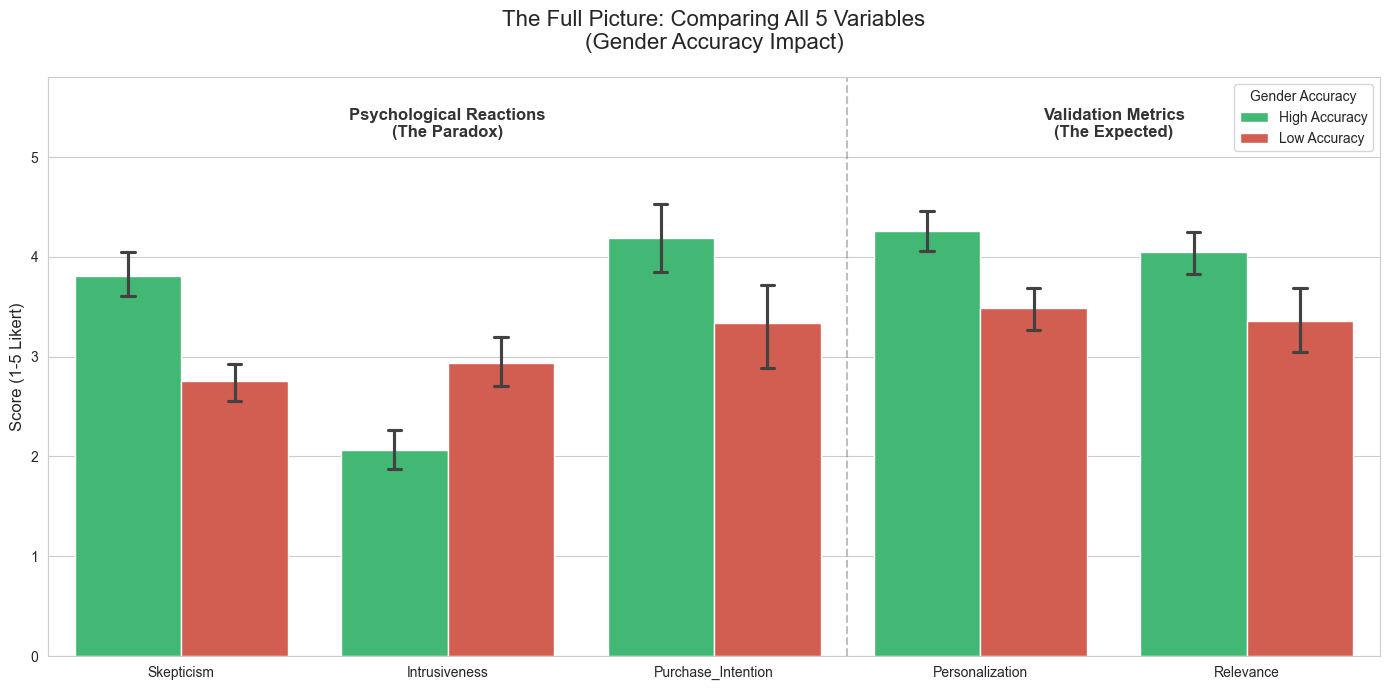

In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# Load Data
df = pd.read_csv('optimized_data_final.csv')

# --- 1. 计算所有 5 个指标 ---
# (注意：Skepticism 依然保持反向计分逻辑：分高=怀疑)

# Skepticism (Reversed)
cols_trust = ['Q1_Trust_Depend', 'Q2_Aim_Inform', 'Q3_Is_Informative', 'Q4_Trust_Truthful', 
              'Q5_Trust_Reliable', 'Q6_Trust_Truth_Well_Told', 'Q7_Trust_True_Picture', 
              'Q8_Trust_Accurately_Informed', 'Q9_Essential_Info']
df['Score_Trust'] = df[cols_trust].mean(axis=1)
df['Skepticism'] = 6 - df['Score_Trust'] 

# Purchase (Q21, Q22 only)
df['Purchase_Intention'] = df[['Q21_Purchase_Thoughts', 'Q22_Purchase_Probability']].mean(axis=1)

# Intrusiveness
cols_intr = ['Q23_Intrusive', 'Q24_Disturbing', 'Q25_Irritating', 'Q26_Invasive', 'Q27_Uncomfortable']
df['Intrusiveness'] = df[cols_intr].mean(axis=1)

# Personalization
cols_pers = ['Q10_Relevance_Matches_Needs', 'Q11_Relevance_Tailor_Made', 'Q12_Relevance_Tailored_Situation', 
             'Q13_Relevance_Unique_Customer', 'Q14_Relevance_Customized_Needs']
df['Personalization'] = df[cols_pers].mean(axis=1)

# Relevance
cols_rel = ['Q15_Beneficial', 'Q16_Important', 'Q17_Useful', 'Q18_Meaningful', 'Q19_Valuable']
df['Relevance'] = df[cols_rel].mean(axis=1)

# Grouping
df['Group_Gender'] = df['Gender_accuracy'].apply(lambda x: 'High Accuracy' if x >= 4 else 'Low Accuracy')

# --- 2. 绘图：全景视角 ---
# 融合数据
metrics = ['Skepticism', 'Intrusiveness', 'Purchase_Intention', 'Personalization', 'Relevance']
df_melt = pd.melt(df, id_vars=['Group_Gender'], value_vars=metrics, var_name='Metric', value_name='Score')

plt.figure(figsize=(14, 7))
sns.set_style("whitegrid")

# 定义颜色：准确(绿), 误读(红)
palette = {'Low Accuracy': '#E74C3C', 'High Accuracy': '#2ECC71'}

ax = sns.barplot(x='Metric', y='Score', hue='Group_Gender', data=df_melt, palette=palette, capsize=.1, errorbar=('ci', 95))

# 添加分割线区分不同性质的变量
plt.axvline(x=2.5, color='gray', linestyle='--', alpha=0.5)
plt.text(1, 5.2, "Psychological Reactions\n(The Paradox)", ha='center', fontsize=12, fontweight='bold', color='#333')
plt.text(3.5, 5.2, "Validation Metrics\n(The Expected)", ha='center', fontsize=12, fontweight='bold', color='#333')

plt.title('The Full Picture: Comparing All 5 Variables\n(Gender Accuracy Impact)', fontsize=16, pad=20)
plt.ylabel('Score (1-5 Likert)', fontsize=12)
plt.xlabel('')
plt.ylim(0, 5.8)
plt.legend(title='Gender Accuracy')

plt.tight_layout()
plt.savefig('viz_all_variables.png', dpi=300)